In [ ]:
"""
Figure 2 - Ice displacement at LEV5, and annual cumulative PDH at KAN_M. 
Author: Hannah Picton 
Date: 26th March 2026
Description: This notebook plots (a) ice displacement at LEV5 between 2009-2012 and 2021-2023, and (b) annual cumulative PDH at KAN_M between 2009 and 2023.
Ice displacement data for 2009-2012 can be found at Tedstone & Nienow (2018; https://doi.org/10.5285/1f69fba3-4c62-47ad-8119-08cfeec05e46) and for 2021-2023 
at Tedstone et al. (2026; https://doi.org/10.5281/zenodo.18611668). PDH data is derived from hourly data from the automatic weather station (AWS) at KAN_M, 
which is made available through PROMICE (http://www.promice.dk).  
"""

# IMPORT REQUIRED LIBRARIES
import os
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np
import glob

# -- PROVIDE PATH TO SEASONAL & ANNUAL ICE DISPLACEMENT DATA --
displacement_data_path = '.../data/' # UPDATE FILEPATH
displacement_folders = ['seasonal_annual_2009_2013', 'seasonal_annual_2020_2024']
site = 'lev5'

# -- PROVIDE PATH TO KAN_M HOURLY DATA --
kan_m_hourly = pd.read_csv('.../data/KAN_M_hour.csv') # UPDATE FILEPATH

In [2]:
# Prepare ice displacement data for plotting
store = [] # Initialize an empty list to store all CSV data
# Loop through folders to find CSV files for the specified site
for folder in displacement_folders:
    fglob = os.path.join(displacement_data_path, folder, f'{site}_seasonal_annual_*.csv')
    files = glob.glob(fglob)
    for fs in files:
        d = pd.read_csv(fs)
        store.append(d)
all_data = pd.concat(store, axis=0) # Combine all dataframes into a single dataframe
# Pivot data to separate each seasonal/annual component
es_data = all_data[(all_data.period == 'ES') & (all_data.site == site)].pivot(index='year', values='disp_m', columns='site')
ls_data = all_data[(all_data.period == 'LS') & (all_data.site == site)].pivot(index='year', values='disp_m', columns='site')
winter_data = all_data[(all_data.period == 'Winter') & (all_data.site == site)].pivot(index='year', values='disp_m', columns='site')
annual_data = all_data[(all_data.period == 'Annual') & (all_data.site == site)].pivot(index='year', values='disp_m', columns='site')
# Map years to numeric positions for plotting on the x-axis
years_disp = [2009, 2010, 2011, 2012, 2021, 2022, 2023]
mapped_years_disp = [0, 1, 2, 3, 4.5, 5.5, 6.5]
year_mapping_disp = dict(zip(years_disp, mapped_years_disp))
for data in [es_data, ls_data, winter_data, annual_data]:
    data['mapped_year'] = data.index.map(year_mapping_disp)


# Calculate PDH from KAN_M hourly data
kan_m_hourly['time'] = pd.to_datetime(kan_m_hourly['time'])
kan_m_hourly.set_index('time', inplace=True)
kan_m_filtered = kan_m_hourly.loc[(kan_m_hourly.index >= '2009-05-01') & (kan_m_hourly.index < '2024-05-01')].copy()
kan_m_filtered['PDH'] = kan_m_filtered['t_u'].clip(lower=0) # Clip negative values for PDH calculation
kan_m_filtered['offset_year'] = (kan_m_filtered.index - pd.DateOffset(months=4)).year
pdh_kan_m_annual = kan_m_filtered.groupby('offset_year')['PDH'].sum() # Calculate cumulative PDH for each year (1 May - 30 April)
mean_pdh_kan_m = pdh_kan_m_annual.mean() # Calculate mean annual cumulative PDH

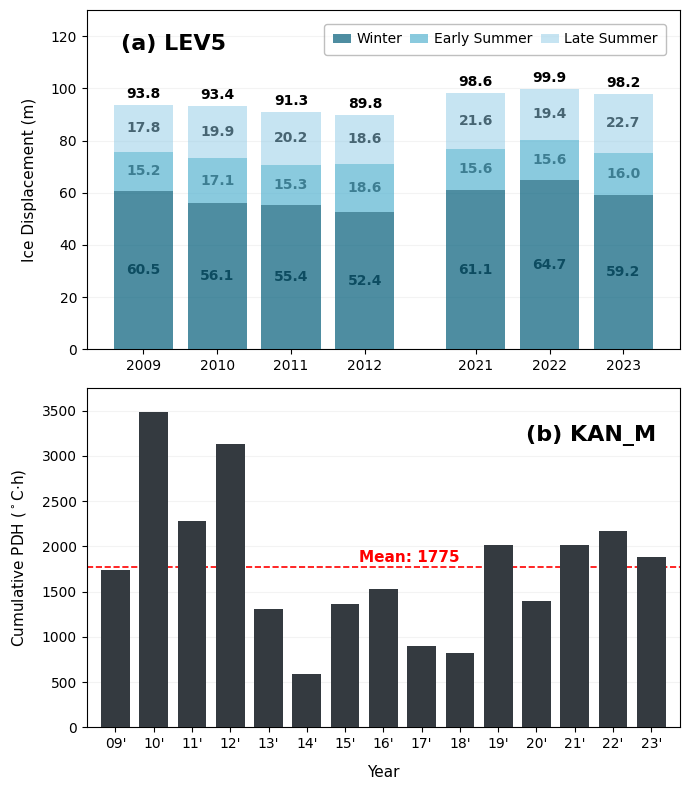

In [8]:
# Plot (a) ice displacement at LEV5 between 2009-2012 and 2021-2023, and (b) annual cumulative PDH at KAN_M between 2009 and 2023.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 8), sharex=False)

# Figure 2a - Ice displacement at LEV5
legend_labels = set()
winter_color = '#126782'
early_summer_color = '#58b4d1'
late_summer_color = '#8ecae6'
hatched_color = '#d2d2d2'

for year in years_disp:
    if year in es_data.index and year in ls_data.index and year in winter_data.index:
        # Winter
        ax1.bar(winter_data.loc[year, 'mapped_year'], winter_data.loc[year, site], color=winter_color, zorder=5, alpha=0.75,
                label='Winter' if 'Winter' not in legend_labels else "")
        # Early Summer
        ax1.bar(es_data.loc[year, 'mapped_year'], es_data.loc[year, site],bottom=winter_data.loc[year, site],
                color=early_summer_color, alpha=0.7, zorder=5, label='Early Summer' if 'Early Summer' not in legend_labels else "")
        # Late Summer
        ax1.bar(ls_data.loc[year, 'mapped_year'], ls_data.loc[year, site], bottom=winter_data.loc[year, site] + es_data.loc[year, site],
                color=late_summer_color, alpha=0.5, zorder=5, label='Late Summer' if 'Late Summer' not in legend_labels else "")
        # Annotate each bar
        winter_mid = winter_data.loc[year, site]/2
        if winter_data.loc[year, site] != 0:
            ax1.annotate(f'{winter_data.loc[year, site]:.1f}', xy=(winter_data.loc[year, 'mapped_year'], winter_mid), ha='center', va='center', fontsize=10, fontweight='bold')
        es_mid = winter_data.loc[year, site] + es_data.loc[year, site]/2
        if es_data.loc[year, site] != 0:
            ax1.annotate(f'{es_data.loc[year, site]:.1f}',
                         xy=(es_data.loc[year, 'mapped_year'], es_mid),
                         ha='center', va='center', fontsize=10, fontweight='bold')
        ls_mid = winter_data.loc[year, site] + es_data.loc[year, site] + ls_data.loc[year, site]/2
        if ls_data.loc[year, site] != 0:
            ax1.annotate(f'{ls_data.loc[year, site]:.1f}',xy=(ls_data.loc[year, 'mapped_year'], ls_mid), ha='center', va='center', fontsize=10, fontweight='bold')
        # Annotate annual ice displacement at top of each stacked bar
        total_height = winter_data.loc[year, site] + es_data.loc[year, site] + ls_data.loc[year, site]
        if year in annual_data.index and annual_data.loc[year, site] > 0:
            ax1.annotate(f'{annual_data.loc[year, site]:.1f}', xy=(ls_data.loc[year, 'mapped_year'], total_height),
                         xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot formatting
ax1.set_xticks(mapped_years_disp)
ax1.set_xticklabels(years_disp)
ax1.set_ylim(0, 130)
ax1.set_ylabel('Ice Displacement (m)', fontsize=11, labelpad=10)
ax1.grid(axis='y', linestyle='-', alpha=0.15, zorder=0)
ax1.text(0.235, 0.93, '(a) LEV5', transform=ax1.transAxes, fontsize=16, fontweight='bold', ha='right', va='top', color='black')
handles, labels = ax1.get_legend_handles_labels()
label_to_handle = dict(zip(labels, handles))
ordered_labels = ['Winter', 'Early Summer', 'Late Summer']
ordered_handles = [label_to_handle[label] for label in ordered_labels if label in label_to_handle]
ax1.legend(handles=ordered_handles, labels=ordered_labels, loc='upper right', fontsize=10, ncol=3, columnspacing=0.6,
          handletextpad=0.4, borderpad=0.6, borderaxespad=1, handlelength=1.3, facecolor='white', framealpha=0.5, edgecolor='grey')

# Figure 2b - Annual cumulative PDH at KAN_M
pdh_plot = pdh_kan_m_annual.loc[2009:2023]
ax2.bar(pdh_plot.index, pdh_plot.values, color='#343a40', alpha=1, width=0.75, zorder=5)
ax2.set_xticks(pdh_plot.index)
ax2.set_xticklabels([f"{str(y)[-2:]}'" for y in pdh_plot.index])
ax2.set_ylabel(r'Cumulative PDH ($^\circ$C$\cdot$h)', fontsize=11, labelpad=10)
ax2.set_xlabel('Year', fontsize=11, labelpad=10)
ax2.set_ylim(0, 3750)
ax2.set_xlim(2008.25, 2023.75)
ax2.grid(axis='y', linestyle='-', alpha=0.15, zorder=0)
ax2.axhline(mean_pdh_kan_m, color='red', linestyle='--', linewidth=1.2,zorder=1) # Add horizontal line for mean PDH
ax2.text(2023 - 5, mean_pdh_kan_m + 20, f'Mean: {mean_pdh_kan_m:.0f}', va='bottom', ha='right', color='red', fontweight='bold', fontsize=11) # Annotate mean PDH value
ax2.text(0.96, 0.89, '(b) KAN_M', transform=ax2.transAxes, fontsize=16, fontweight='bold', ha='right', va='top') # Annotate subplot label

plt.tight_layout()
plt.show()